# 03 — Data Cleaning and Preprocessing
**Day 3 · Phase 2: Data Preprocessing and Feature Engineering**

### Objectives
Turn the raw file into an analysis-ready table, with every change justified by evidence and logged.

### Principles
- The raw CSV is never modified; cleaning produces `data/processed/phones_clean.csv`.
- All rules live in **`src/preprocessing.py` → `clean_dataset()`**, so notebooks, the training script and tests
  apply identical logic. This notebook shows the evidence for each rule and verifies the result.
- Each anomaly is classified as one of: **formatting problem · data-entry error · genuine extreme · unusual but valid**.
  Only errors are corrected; extremes are kept.
- No rule uses the target (price) to decide a feature's value, so no target information leaks into features.

In [1]:
import sys, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.plot_style import (apply_style, save_fig, rupee_axis, PALETTE, PRIMARY, ACCENT,
                            NEUTRAL, DIVERGING, SEQUENTIAL)

apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
RANDOM_STATE = 42

from src.data_loader import load_raw_data
from src.preprocessing import (clean_dataset, parse_price, parse_megapixels, normalise_text, RENAME_MAP,
                               ENCODING_FIXES, MODEL_NAME_FIXES, is_feature_phone)
raw = load_raw_data()
print("Raw shape:", raw.shape)

Raw shape: (541, 12)


## 1. Missing-value analysis
Day 1 found **no NaNs** but several kinds of *disguised* missingness. Here's how each is handled:

| Disguised value | Rows | Decision |
|---|---|---|
| `0MP` camera | 10 rear / 16 front | Valid — the phone has no camera. All are feature phones (out of scope after §6). |
| Processor = OS / core count only (`Oxygen OS`, `Android`, `Octa Core`, …) | ~12 after scoping | Keep the row; processor tier becomes **NaN** and is **median-imputed inside the training pipeline** (Day 4). Vendor = “Unknown”. |
| Colour `M3)` | 5 | Replace with `Unknown` (colour is not used as a feature). |
| Implausible RAM (§7) | 15 | Set to NaN → imputed inside the pipeline using the **training** median only. |

Imputation happens inside the model pipeline (not here) so the imputed value is learned from training folds only.

## 2. Type corrections: price and cameras

In [2]:
price = parse_price(raw["Prize"])
rear = parse_megapixels(raw["Rear Camera"])
front = parse_megapixels(raw["Front Camera"])
pd.DataFrame({"raw Prize": raw["Prize"].head(4), "price": price.head(4),
              "raw Rear Camera": raw["Rear Camera"].head(4), "rear_camera_mp": rear.head(4)})

,raw Prize,price,raw Rear Camera,rear_camera_mp
0,"7,299",7299,13MP,13
1,"7,299",7299,13MP,13
2,"11,999",11999,50MP,50
3,"5,649",5649,8MP,8


`parse_price` and `parse_megapixels` **raise an error** if any value fails to parse, rather than silently creating
NaNs. All 541 values convert.

## 3. Text consistency: whitespace, encoding, case, model-name errors

In [3]:
proc_before = raw["Processor_"].nunique()
proc_after = normalise_text(raw["Processor_"]).nunique()
print(f"Processor strings: {proc_before} raw -> {proc_after} after whitespace/encoding normalisation")
print("Processor values with leading/trailing spaces before:", int((raw["Processor_"] != raw["Processor_"].str.strip()).sum()))
print("\nEncoding repairs:")
for k, v in ENCODING_FIXES.items():
    print(f"  {k!r} -> {v!r}")
print("\nModel-name repairs:")
for k, v in MODEL_NAME_FIXES.items():
    print(f"  {k!r} -> {v!r}")

Processor strings: 123 raw -> 123 after whitespace/encoding normalisation
Processor values with leading/trailing spaces before: 18

Encoding repairs:
  '7Â° Purple' -> '7° Purple'
  'QualcommÂ® Snapdragonâ_x0084_¢ 765G' -> 'Qualcomm Snapdragon 765G'

Model-name repairs:
  'vivo Y565G' -> 'vivo Y56 5G'
  'I Kall Z19Pro Flash blue' -> 'I Kall Z19Pro'
  'micromax1' -> 'micromax 1'


In [4]:
# Evidence for 'vivo Y565G' -> 'vivo Y56 5G': same colour, specs and price band as the Y56 5G rows.
raw[raw["Model"].str.contains("Y56", case=False)][["Model", "Colour", "Memory", "RAM", "Battery_", "Processor_", "Prize"]]

,Model,Colour,Memory,RAM,Battery_,Processor_,Prize
405,vivo Y56 5G,Black Engine,128,8,5000,Mediatek Dimensity 700,"19,999"
428,vivo Y56 5G,Orange Shimmer,128,8,5000,Mediatek Dimensity 700,"19,999"
429,vivo Y56 5G,Black Engine,128,4,5000,Mediatek Dimensity 700,"17,999"
468,vivo Y56 5G,Orange Shimmer,128,4,5000,Mediatek Dimensity 700,"17,999"
490,vivo Y565G,Orange Shimmer,128,8,5000,MTK Dimensity 700,"19,979"


**Decisions.**
- Whitespace collapse + encoding repair fixes the 18 trailing spaces and the two mis-encoded strings (`7Â° Purple`,
  `QualcommÂ® Snapdragonâ_x0084_¢ 765G`). This doesn't reduce the number of distinct processor strings (the
  space-padded values had no unpadded twin). The real fragmentation — *Snapdragon 680* written several ways, the typo
  *Meditek* — is handled on Day 4 by vendor/tier extraction, which is robust to spelling.
- `vivo Y565G` is a typo for `vivo Y56 5G` (identical colour “Orange Shimmer”, 128/8, 5000 mAh, Dimensity 700, price
  ₹19,979 vs ₹19,999). `I Kall Z19Pro Flash blue` has the colour inside its name. `micromax1` lacks a space.
- **Case differences in model names** (`OPPO A17k` / `OPPO A17K`) are kept as displayed but grouped via a lower-case
  `model_key`, used for duplicate detection and grouped validation.
- Colours are title-cased (`FLASH BLUE` → `Flash Blue`).

## 4. The mislabelled model

In [5]:
cols = ["Model", "Colour", "Memory", "RAM", "Battery_", "Rear Camera", "Front Camera", "Mobile Height", "Processor_", "Prize"]
raw[raw["Model"].str.contains("Pixel 6a|nothing", case=False)][cols]

,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,Mobile Height,Processor_,Prize
135,Google Pixel 6a,Chalk,128,6,4410,12MP,8MP,15.600,Google Tensor,"28,999"
136,Google Pixel 6a,Charcoal,128,6,4410,12MP,8MP,15.600,Google Tensor,"28,999"
328,nothing phone 1,White,128,8,4500,50MP,16MP,16.640,Qualcomm Snapdragon 778G+,"30,499"
329,Google Pixel 6a,chalk,128,8,4500,50MP,16MP,16.640,Qualcomm Snapdragon 778G+,"30,999"
342,nothing phone 1,Black,128,8,4500,50MP,16MP,16.640,Qualcomm Snapdragon 778G+,"29,499"


**Classification: labelling error.** The *chalk* “Google Pixel 6a” row matches *nothing phone 1* on all seven
specification fields and sits inside its price range (₹29,499–₹30,499 vs ₹30,999). It shares nothing with the real
Pixel 6a rows (Tensor chip, 12 MP, 4410 mAh). The specs and price are self-consistent, so the row is kept and the
**label is corrected** — otherwise it would teach the model that a Google phone has Snapdragon specs, and it would
place a “Pixel 6a” in the wrong group for validation. The rule in `clean_dataset` only relabels a Pixel 6a row
when every spec field equals a nothing phone 1 row.

## 5. Outlier investigation

In [6]:
tmp = raw.rename(columns=RENAME_MAP).assign(price=price, rear_camera_mp=rear, front_camera_mp=front)
num = ["storage_gb", "ram_gb", "battery_mah", "rear_camera_mp", "front_camera_mp", "display_size_cm", "price"]
q1, q3 = tmp[num].quantile(0.25), tmp[num].quantile(0.75)
iqr = q3 - q1
iqr_flag = (tmp[num] < q1 - 1.5 * iqr) | (tmp[num] > q3 + 1.5 * iqr)

# Robust z-score: (x - median) / (1.4826 * MAD). Unlike the ordinary z-score, it isn't distorted by the outliers it looks for.
mad = (tmp[num] - tmp[num].median()).abs().median()
robust_z = (tmp[num] - tmp[num].median()) / (1.4826 * mad.replace(0, np.nan))
outliers = pd.DataFrame({"IQR flags": iqr_flag.sum(), "|robust z| > 3.5": (robust_z.abs() > 3.5).sum(),
                         "MAD = 0 (spike distribution)": mad.eq(0)})
outliers

,IQR flags,|robust z| > 3.5,MAD = 0 (spike distribution)
storage_gb,55,0,False
ram_gb,0,0,False
battery_mah,152,0,True
rear_camera_mp,39,248,False
front_camera_mp,13,35,False
display_size_cm,33,30,False
price,25,21,False


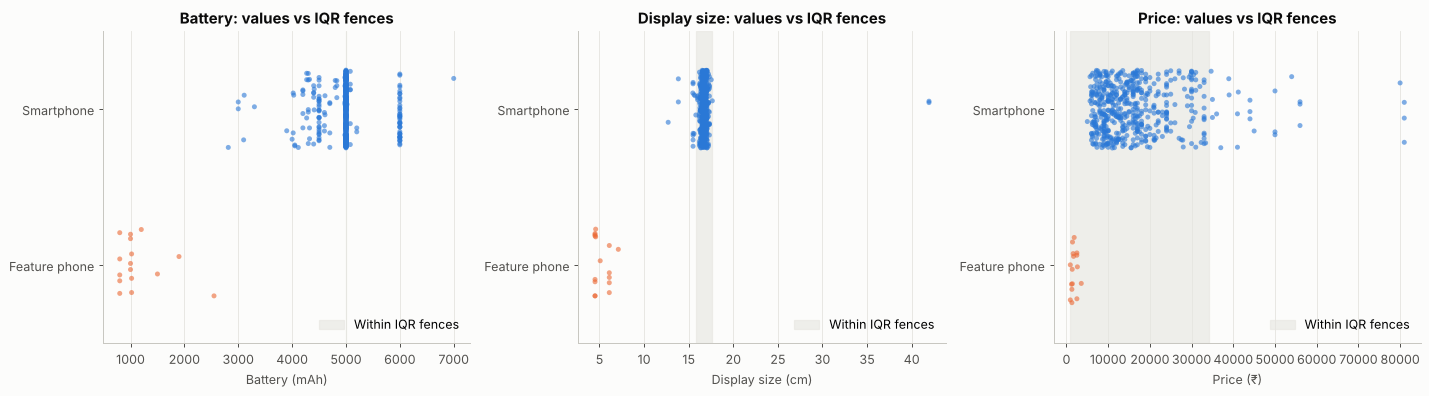

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
seg = np.where(is_feature_phone(tmp), "Feature phone", "Smartphone")
for ax, col, title, unit in [(axes[0], "battery_mah", "Battery", "mAh"), (axes[1], "display_size_cm", "Display size", "cm"),
                             (axes[2], "price", "Price", "₹")]:
    sns.stripplot(x=tmp[col], y=seg, ax=ax, hue=seg, palette=[PRIMARY, ACCENT], size=4, alpha=0.6, jitter=0.25, legend=False)
    lo, hi = q1[col] - 1.5 * iqr[col], q3[col] + 1.5 * iqr[col]
    ax.axvspan(max(lo, tmp[col].min()), hi, color="#e6e5e0", alpha=0.6, zorder=0, label="Within IQR fences")
    ax.set(title=f"{title}: values vs IQR fences", xlabel=f"{title} ({unit})", ylabel="")
    ax.legend(loc="lower right")
fig.tight_layout(); save_fig(fig, "cleaning_outlier_review")

**Classification of what the outlier rules flag:**

| Flagged values | Class | Action |
|---|---|---|
| Price > ₹34,265 (25 premium phones) | Genuine extreme | **Keep** — removing them would make premium pricing impossible |
| Battery ≠ 5,000 mAh (IQR flags 152 because the distribution is a spike; MAD = 0) | Unusual but valid (4,000–4,500 flagships, 6,000–7,000 budget phones) | **Keep** |
| Battery < 2,600 mAh, display < 10 cm | Different product category (feature phones) | **Exclude by scope** (§6) |
| Display = 41.94 cm | Data-entry error | **Correct** to 16.64 (same model's other rows) |
| Rear camera 108/200 MP | Unusual but valid (real high-res sensors) | **Keep** |

The IQR and robust z-score rules disagree a lot here (spiky, discrete data), which is why outliers were judged
individually rather than removed by a threshold.

## 6. Duplicates and scope (feature phones)

In [8]:
fp = tmp[is_feature_phone(tmp)]
print("Feature-phone rows:", len(fp))
print("Median price:", f"₹{fp['price'].median():,.0f}", "| storage values recorded:", sorted(int(v) for v in fp["storage_gb"].unique()),
      "| RAM values recorded:", sorted(int(v) for v in fp["ram_gb"].unique()))
print("(16 rows here; one is also a duplicate, so 15 are excluded by the scope rule after de-duplication)")

Feature-phone rows: 16
Median price: ₹1,524 | storage values recorded: [16, 32, 64, 128, 256] | RAM values recorded: [3, 4, 6, 8]
(16 rows here; one is also a duplicate, so 15 are excluded by the scope rule after de-duplication)


**Decision: the model covers smartphones only.** Reasons:
1. Day 1 showed the feature-phone rows' **colour, storage and RAM are copied from the preceding listing** (e.g. a
   ₹1,299 phone recorded with 256 GB / 8 GB). Their true values (measured in MB) are not in the data, so keeping
   them would teach the model that 256 GB can cost ₹1,299.
2. They are a different product category (no camera, 4.5–7 cm screens) with a different price mechanism.
3. They are only ~3 % of rows.

This is documented as a **scope limitation**: the model must not be used to price feature phones. Excluded rows are
saved in `data/processed/excluded_rows.csv` for traceability.

**Duplicates:** after text normalisation, rows identical on every field are the same listing captured twice and are
removed (keeping the first). Same-specification listings with *different* prices are kept: that's real price variation.

## 7. Implausible RAM values

In [9]:
t = tmp.copy(); t["model"] = normalise_text(t["model"])
rule_a = (t["storage_gb"] == 256) & (t["ram_gb"] <= 4) & ~is_feature_phone(t)
rule_b = t["model"].str.upper().str.startswith("APPLE")
t[rule_a | rule_b][["model", "storage_gb", "ram_gb", "processor", "price"]].assign(rule=np.where(rule_b[rule_a | rule_b], "B: Apple", "A: 256 GB / ≤4 GB"))

,model,storage_gb,ram_gb,processor,price,rule
272,REDMI Note 12 Pro+ 5G,256,4,Mediatek Dimensity 1080,32999,A: 256 GB / ≤4 GB
283,REDMI Note 12 Pro+ 5G,256,2,Mediatek Dimensity 1080,32999,A: 256 GB / ≤4 GB
358,REDMI Note 12 Pro+ 5G,256,4,Mediatek Dimensity 1080,32999,A: 256 GB / ≤4 GB
364,vivo V23 5G,256,4,Mediatek Dimensity 920,27540,A: 256 GB / ≤4 GB
396,vivo V27 5G,256,4,Mediatek Dimensity 7200 5G,36999,A: 256 GB / ≤4 GB
400,MOTOROLA Edge 30 Ultra,256,4,Qualcomm Snapdragon 8+ Gen 1,49999,A: 256 GB / ≤4 GB
408,POCO F5 5G,256,4,Qualcomm Snapdragon 7+ Gen 2 (4nm),32999,A: 256 GB / ≤4 GB
450,realme X3 SuperZoom,256,3,Qualcomm Snapdragon 855,17999,A: 256 GB / ≤4 GB
464,realme GT 2,256,2,Qualcomm Snapdragon 888,32299,A: 256 GB / ≤4 GB
474,APPLE iPhone 11,64,8,ios,41199,B: Apple


**Classification: data errors (scraping).**
- **Rule A** — a 256 GB smartphone recorded with ≤ 4 GB RAM. These are upper-mid/flagship phones (POCO F5,
  Note 12 Pro+, Edge 30 Ultra, GT 2), and several of them have the *same* model listed elsewhere in the data with 8 GB
  at a *lower* price. The values are consistent with “12 GB” losing its first digit.
- **Rule B** — Apple rows: the same iPhone 14 Plus at the same price is recorded with 3, 4 and 6 GB, so the column
  carries no reliable information for Apple.

**Treatment: set to missing, not overwritten.** We don't know the true values from this dataset, and importing them
from outside sources would mix data provenance. Setting NaN lets the pipeline impute from the training median. The
rows' other fields (price, storage, processor) remain useful. Neither rule looks at price, so this doesn't leak the
target into the features. **Effect on interpretation:** RAM's importance may be slightly understated.

## 8. Run the full cleaning function and verify

In [10]:
clean, excluded, log = clean_dataset(raw)
log.to_frame()

,step,rows_affected,detail
0,Drop 'Unnamed: 0' and rename columns,541,index artefact; snake_case names
1,Convert price and camera strings to integers,541,"'7,299' -> 7299; '50MP' -> 50"
2,"Normalise whitespace, fix encoding and 3 model...",23,
3,Title-case colours; 'M3)' -> 'Unknown',5,
4,Relabel 'Google Pixel 6a' row with Nothing Pho...,1,all spec fields identical to nothing phone 1 rows
5,Replace impossible display size (41.94 cm) wit...,2,
6,Drop duplicate listings (all fields identical),10,
7,Exclude feature phones (battery < 2600 mAh or ...,15,unreliable storage/RAM; different product cate...
8,Set implausible RAM to missing (256 GB with <=...,15,imputed with training median inside the pipeline


In [11]:
checks = {
    "rows: 541 raw -> clean": len(clean),
    "excluded rows": len(excluded),
    "excluded by reason": excluded["reason"].value_counts().to_dict(),
    "duplicate rows remaining": int(clean.duplicated().sum()),
    "display_size_cm max (expect < 20)": clean["display_size_cm"].max(),
    "battery_mah min (expect >= 2600)": clean["battery_mah"].min(),
    "price dtype": str(clean["price"].dtype),
    "NaN per column": {k: int(v) for k, v in clean.isna().sum().items() if v},
    "distinct models (model_key)": clean["model_key"].nunique(),
    "non-ASCII text remaining": int(clean[["model", "colour", "processor"]].map(lambda s: not str(s).isascii()).any(axis=1).sum()),
}
for k, v in checks.items():
    print(f"{k:38s}: {v}")

assert clean["display_size_cm"].max() < 20
assert clean["battery_mah"].min() >= 2600
assert not clean.duplicated().any()
assert clean["price"].gt(0).all()

rows: 541 raw -> clean                : 516
excluded rows                         : 25
excluded by reason                    : {'feature phone (out of scope)': 15, 'duplicate listing': 10}
duplicate rows remaining              : 0
display_size_cm max (expect < 20)     : 17.65
battery_mah min (expect >= 2600)      : 2815
price dtype                           : int64
NaN per column                        : {'ram_gb': 15}
distinct models (model_key)           : 172
non-ASCII text remaining              : 1


**Verification.** 516 smartphone rows remain (10 duplicates + 15 feature phones removed). Every assertion passes.
The only NaNs are the 15 deliberately-blanked RAM values. One non-ASCII value remains intentionally (`7° Purple`,
a correctly-encoded degree sign).

In [12]:
display(clean.head())
clean.describe().T

,model,colour,storage_gb,ram_gb,battery_mah,rear_camera_mp,front_camera_mp,ai_lens,display_size_cm,processor,price,model_key
0,Infinix SMART 7,Night Black,64,4.000,6000,13,5,1,16.760,Unisoc Spreadtrum SC9863A1,7299,infinix smart 7
1,Infinix SMART 7,Azure Blue,64,4.000,6000,13,5,1,16.760,Unisoc Spreadtrum SC9863A1,7299,infinix smart 7
2,MOTOROLA G32,Mineral Gray,128,8.000,5000,50,16,0,16.640,Qualcomm Snapdragon 680,11999,motorola g32
3,POCO C50,Royal Blue,32,2.000,5000,8,5,0,16.560,Mediatek Helio A22,5649,poco c50
4,Infinix HOT 30i,Marigold,128,8.000,5000,50,5,1,16.760,G37,8999,infinix hot 30i


,count,mean,std,min,25%,50%,75%,max
storage_gb,516.000,111.132,59.927,16.000,64.000,128.000,128.000,256.000
ram_gb,501.000,5.445,1.991,2.000,4.000,6.000,8.000,8.000
battery_mah,516.000,"4,982.207",425.282,"2,815.000","5,000.000","5,000.000","5,000.000","7,000.000"
rear_camera_mp,516.000,47.548,30.859,5.000,38.000,50.000,50.000,200.000
front_camera_mp,516.000,12.395,8.998,2.000,5.000,8.000,16.000,60.000
ai_lens,516.000,0.066,0.248,0.000,0.000,0.000,0.000,1.000
display_size_cm,516.000,16.678,0.390,12.700,16.510,16.760,16.940,17.650
price,516.000,"16,725.979","10,714.865","4,999.000","9,499.000","13,999.000","19,981.750","80,999.000"


## 9. Save outputs

In [13]:
out_dir = PROJECT_ROOT / "data" / "processed"
out_dir.mkdir(parents=True, exist_ok=True)
clean.to_csv(out_dir / "phones_clean.csv", index=False)
excluded.to_csv(out_dir / "excluded_rows.csv", index=False)
log.to_frame().to_csv(out_dir / "cleaning_log.csv", index=False)
print([p.name for p in sorted(out_dir.iterdir())])

['cleaning_log.csv', 'excluded_rows.csv', 'features_train.csv', 'phones_clean.csv', 'phones_model_ready.csv']


## Summary
| Step | Type of issue | Rows |
|---|---|---|
| Drop `Unnamed: 0`, rename to snake_case | artefact / readability | all |
| Price & camera strings → integers | formatting | all |
| Whitespace, encoding, 3 model-name fixes, colour case | formatting / entry error | see log |
| Relabel Pixel 6a row with Nothing Phone 1 specs | labelling error | 1 |
| Display 41.94 → 16.64 cm | entry error | 2 |
| Drop duplicate listings | duplicate | 10 |
| Exclude feature phones | scope (unreliable values) | 15 |
| RAM → NaN (256 GB/≤4 GB; Apple) | scraping error | 15 |
| Premium prices, 6–7k mAh batteries, 108/200 MP | genuine / valid extremes | kept |

Full log: `data/processed/cleaning_log.csv` and `reports/data_cleaning_log.md`.